<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
UE L2 Projet de Statistique CMI OSIA
</div>

</a>
<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Année 2026-2027
</div>
<div style="color: blue; font-size: 1.5em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Nom : du Reau - Prénom : Baptiste

Nom : Caillot - Prénom : Aïdan
</div>


Modèle de compte-rendu du projet avec codes commentés, sorties numériques et graphiques

**Noms et coordonnées des stations**

In [1]:
import pandas as pd

stations_toulouse = pd.read_parquet("stations_toulouse.parquet")

In [2]:
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")

In [3]:
history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Affichage du nombre maximal de vélos disponibles par station
</div>
Création d'une fonction pour afficher des cartes facilement (pas de duplication de code)

In [4]:
import folium
import branca.colormap as cm

def carte_coloree(data, legende, min_1 = None, max_1 = None):
    stations_toulouse["data"] = (
        stations_toulouse["station"].map(data)
    )

    if min_1 == None:
        min_1 = stations_toulouse["data"].min()

    if max_1 == None:
        max_1 = stations_toulouse["data"].max()
        
    # Carte centrée sur les stations
    m = folium.Map(
        location=[
            stations_toulouse["latitude"].mean(),
            stations_toulouse["longitude"].mean()
        ],
        zoom_start=12
    )
    
    # Échelle de couleurs basée sur le nombre maximum de vélos
    colormap = cm.LinearColormap(
        colors=["blue", "cyan", "yellow", "orange", "red"],
        vmin=min_1,
        vmax=max_1,
        caption=legende
    )
    
    # Ajouter les stations
    for _, row in stations_toulouse.dropna(
        subset=["data"]
    ).iterrows():
    
        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=6,
            color=colormap(row["data"]),
            fill=True,
            fill_color=colormap(row["data"]),
            fill_opacity=0.8,
            popup=folium.Popup(
                f"""
                <b>Station :</b> {row['station']}<br>
                <b>ID :</b> {row['station_id']}<br>
                <b>Nombre de vélos :</b>
                {row['data']}
                """,
                max_width=300
            ),
            tooltip=(
                f"{row['station']} : "
                f"{row['data']} vélos"
            )
        ).add_to(m)
    
    # Ajouter la légende
    colormap.add_to(m)
    
    return m

Création d'une nouvelle colonne "nombre_max_velos" dans le dataframe stations_toulouse contenant le nombre max de vélos par station

In [5]:
max_velos = (
    history_toulouse_train
    .groupby(level="station")
    .max()
    .copy()
)
max_bikes = max_velos["bikes"]


m = carte_coloree(max_bikes, "Nombre de vélos")
m

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Valeurs manquantes dans les données
</div>
On constate que stations_toulouse contient 63 stations de plus que history_toulouse_train et history_toulouse_test

In [6]:
print(history_toulouse_train.isna().sum())
stations_toulouse[:3].isna().sum()

bikes     0
stands    0
dtype: int64


station       0
longitude     0
latitude      0
station_id    0
data          0
dtype: int64

On constate que il n'y a pas de valeurs manquantes

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Nombres de mesures pour chaque station et histogramme de leur répartition
</div>

                                    bikes  stands
station                                          
00001 - POIDS DE L'HUILE           104775  104775
00002 - LAFAYETTE                  104783  104783
00003 - ALSACE - LORRAINE - POMME   36008   36008
00003 - ALSACE-LORRAINE - POMME     25278   25278
00003 - POMME                       49799   49799
...                                   ...     ...
NARBONNE - CLOTASSES                  885     885
PASTEUR - LAVOISIER                    98      98
PLACE GEORGES BRASSENS                  8       8
SERVANTY AIRBUS TRAMWAY               301     301
TEST BEE                              192     192

[800 rows x 2 columns]


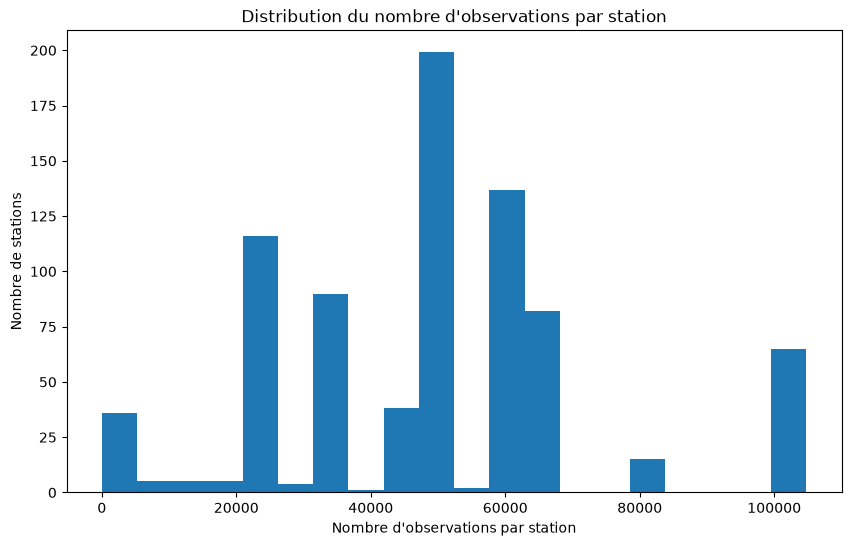

In [7]:
nb_obs = (
    history_toulouse_train
    .groupby(level="station")
    .count()
)

print(nb_obs)

vect_nb_obs = nb_obs["bikes"]

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(vect_nb_obs, bins=20)

plt.xlabel("Nombre d'observations par station")
plt.ylabel("Nombre de stations")
plt.title("Distribution du nombre d'observations par station")

plt.show()

On voit que la plupart des stations ont un nombre d'observation qui varies entre 20 000 et 70 000 mais qu'il existe tout de même un nombre proche de 0 ou de 100 000.

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Dates de début et de fin des mesures par stations et représentation graphique de leur dispersion
</div>

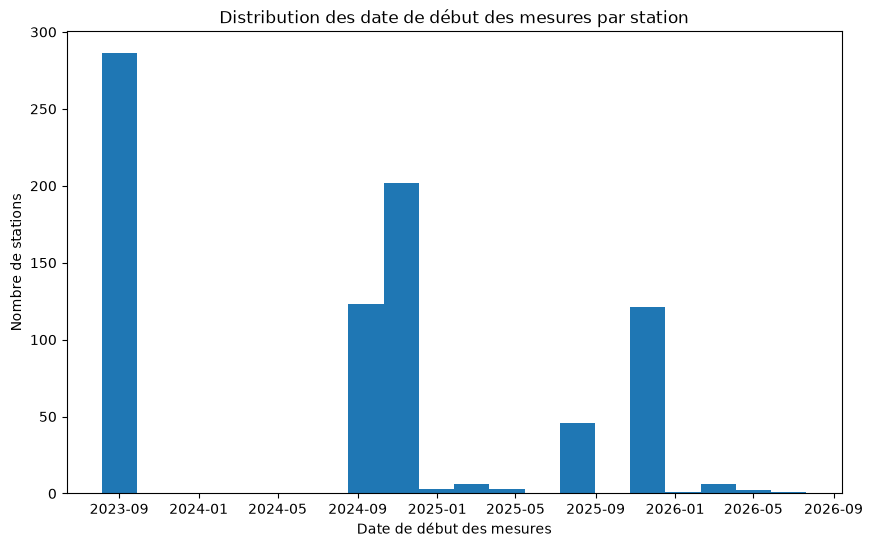

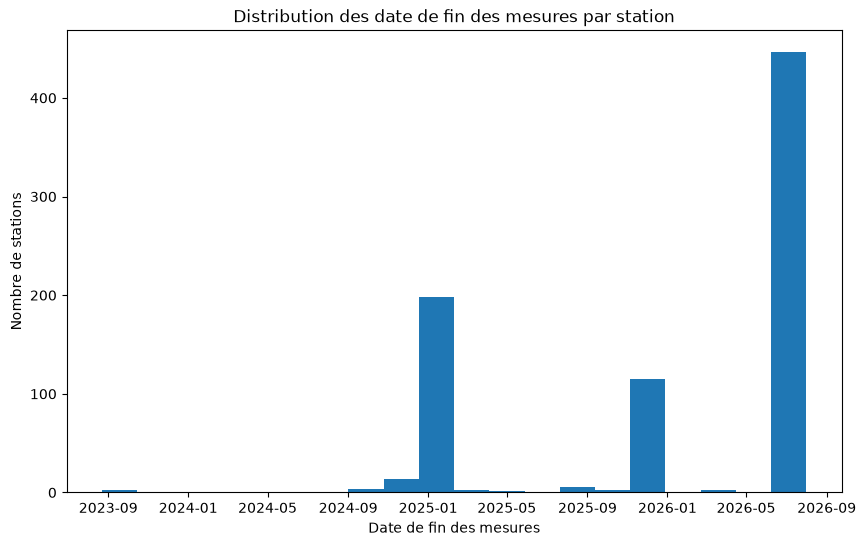

In [8]:
heure_debut = history_toulouse_train.groupby(level = "station").head(1).index.get_level_values("commit_at")
heure_fin = history_toulouse_train.groupby(level = "station").tail(1).index.get_level_values("commit_at")

plt.figure(figsize=(10, 6))

plt.hist(heure_debut, bins=20)

plt.xlabel("Date de début des mesures")
plt.ylabel("Nombre de stations")
plt.title("Distribution des date de début des mesures par station")

plt.show()

plt.figure(figsize=(10, 6))

plt.hist(heure_fin, bins=20)

plt.xlabel("Date de fin des mesures")
plt.ylabel("Nombre de stations")
plt.title("Distribution des date de fin des mesures par station")

plt.show()

Ces graphiques nous montrent qu'une moitié des stations ont des valeurs commençant a partir de septembre 2023 et une autre entre septembre et decembre 2024. De plus l'autre graphique nous indique que plus de 2/3 des stations ont des valeurs jusqu'en juillet-aout 2026 et quelque une en janvier 2025. 

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Statistique de base par station
</div>

In [55]:
min_velos = (
    history_toulouse_train
    .groupby(level="station")
    .min()
    .copy()
)
mean_velos = (
    history_toulouse_train
    .groupby(level="station")
    .mean()
    .copy()
)
ecart_type_velos = (
    history_toulouse_train
    .groupby(level="station")
    .std()
    .copy()
)
premier_quartile_velos = (
    history_toulouse_train
    .groupby(level="station")
    .quantile(0.25)
    .copy()
)
mediane_velos = (
    history_toulouse_train
    .groupby(level="station")
    .quantile(0.5)
    .copy()
)
dernier_quartile_velos = (
    history_toulouse_train
    .groupby(level="station")
    .quantile(0.75)
    .copy()
)


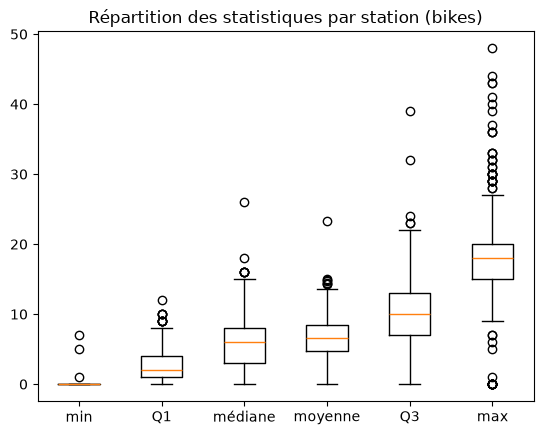

In [53]:
plt.boxplot(
    [
        min_velos["bikes"],
        premier_quartile_velos["bikes"],
        mediane_velos["bikes"],
        mean_velos["bikes"],
        dernier_quartile_velos["bikes"],
                max_velos["bikes"],
    ],
    tick_labels=["min", "Q1", "médiane", "moyenne", "Q3", "max"],
)
plt.title("Répartition des statistiques par station (bikes)")
plt.show()

On observe donc que la majorité des stations se trouve dans les boites et les moustaches, cela nous permet de voir que les statistiques du nombre de vélos des stations sont assez proche entre elles. il y a quand meme le graphique du max qui comporte des valeurs assez eloignées representé par les ronds, donc cela montre que les valeurs statistiques de certaines stations sont assez ecarté de la norme.

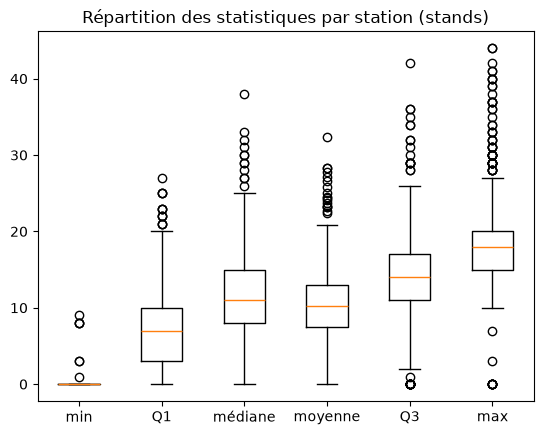

In [54]:
plt.boxplot(
    [
        min_velos["stands"],
        premier_quartile_velos["stands"],
        mediane_velos["stands"],
        mean_velos["stands"],
        dernier_quartile_velos["stands"],
        max_velos["stands"],
    ],
    tick_labels=["min", "Q1", "médiane", "moyenne", "Q3", "max"],
)
plt.title("Répartition des statistiques par station (stands)")
plt.show()

Comme avec les statistiques des vélos, on observe que la majorité des stations se trouve dans les boites et les moustaches ainsi que les valeurs des velos manquants qui sont assez regroupées. Mais contrairement a l'autre graphique, il y a quand meme plus de valeurs eloignées, qui sont hors norme.

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Courbe moyenne journalière de remplissage d'une station (toutes les 15 minutes), et de l'ensemble des stations / calculer également la courbe médiane, 1er-quartile, 3-ème quartile
</div>
Courbe de la moyenne journalière de remplissage d'une station

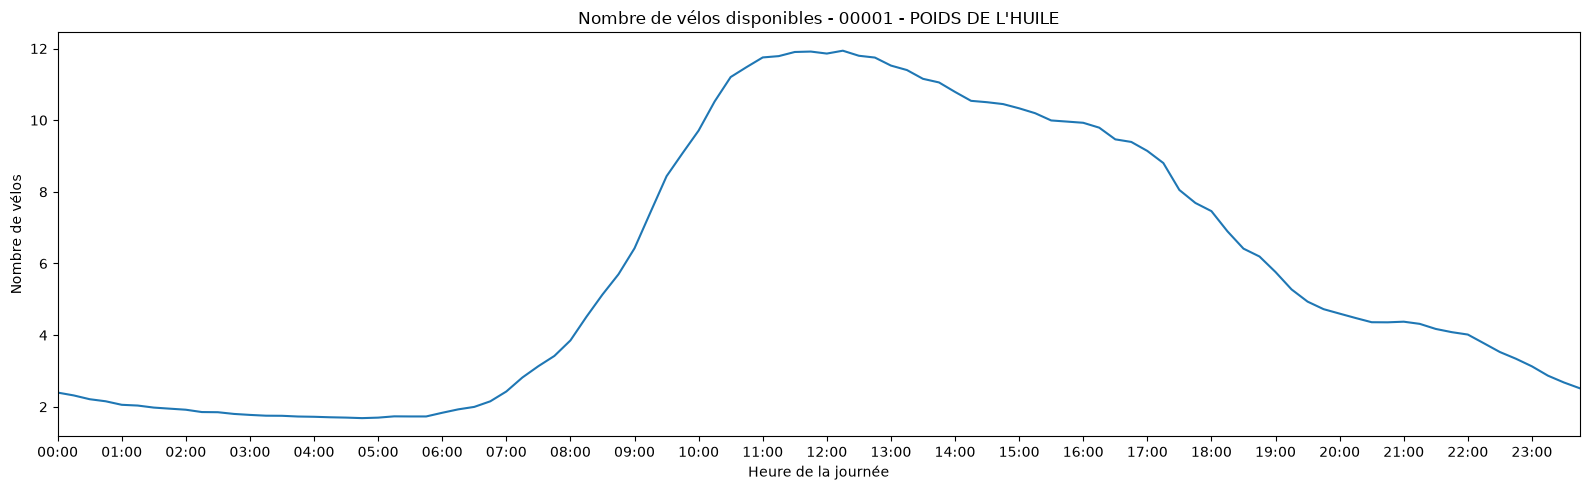

In [75]:
# On convertit les indexes en colonnes classiques
train = history_toulouse_train.reset_index()

# On extrait les heures et les minutes
train["heure"] = train["commit_at"].dt.hour
train["minutes"] = train["commit_at"].dt.minute

# Moyenne par quart d'heure de chaque station
moyenne_station_heure = train.groupby(["station", "heure", "minutes"])["bikes"].mean()

# Nom d'une station que l'on souhaite étudier
station = "00001 - POIDS DE L'HUILE"

# Sélection de toutes les observations de cette station
donnees_station = moyenne_station_heure.loc[station]
liste_minutes = [heure * 60 + minute for heure, minute in donnees_station.index]

plt.figure(figsize=(16, 5))

plt.plot(liste_minutes, donnees_station.values)

plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de vélos")
plt.title(f"Nombre de vélos disponibles - {station}")

# La courbe commence et finit aux bords du graphique
plt.margins(x=0)

# Une étiquette par heure : positions en minutes, texte au format HH:MM
positions = range(0, 24 * 60, 60)
etiquettes = [f"{m // 60:02d}:{m % 60:02d}" for m in positions]
plt.xticks(positions, etiquettes)

plt.tight_layout()
plt.show()

on remarque que pendant les heures de travail beaucoup de velos sont disponible en station contrairement aux autres heures nocturne où le nombre de vélos est minime. On pourrait donc se dire que les personnes prennent des vélos pour rentrer chez eux, étant donné que la station se trouve en centre ville.

Courbe de la moyenne journalière de remplissage de l'ensemble des stations

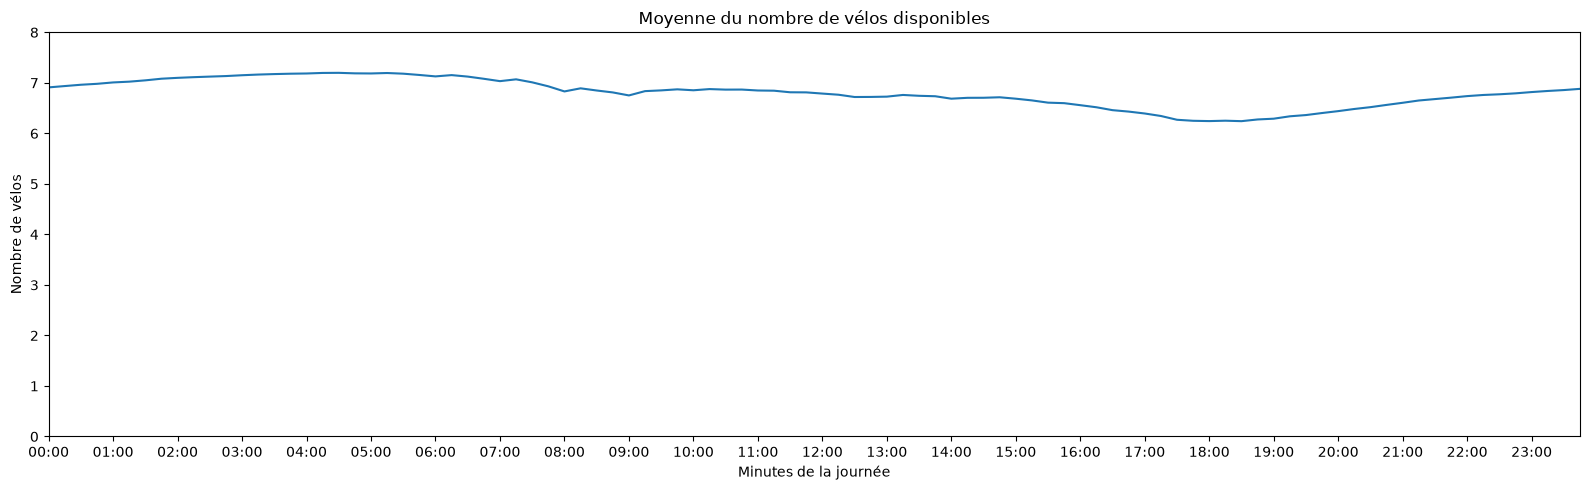

In [77]:
# Moyenne par quart d'heure de l'ensemble des stations
moyenne_station_heure = train.groupby(["heure", "minutes"])["bikes"].mean()

# Étiquettes au format HH:MM (0:0 devient 00:00)
liste_minutes = [f"{heure:02d}:{minute:02d}" for heure, minute in moyenne_station_heure.index]

plt.figure(figsize=(16, 5))

plt.plot(liste_minutes, moyenne_station_heure.values)

plt.xlabel("Minutes de la journée")
plt.ylabel("Nombre de vélos")
plt.title("Moyenne du nombre de vélos disponibles")

# La courbe commence et finit aux bords du graphique
plt.margins(x=0)

# Une étiquette par heure (toutes les 4 mesures de 15 min) pour rester lisible
plt.xticks(range(0, len(liste_minutes), 4), liste_minutes[::4])
plt.ylim(0, 8)

plt.tight_layout()
plt.show()

Ce graphique nous dis qu'en moyenne à toute les heures de la journées le nombres de vélos reste constant. On observe qu'elque petit creux qui représente les moment ou le plus de velos sont pris en meme temps, (8h et 18-19h, les heures d'embauche et de débauche).

Courbe du premier quartile journalière de remplissage de l'ensemble des stations

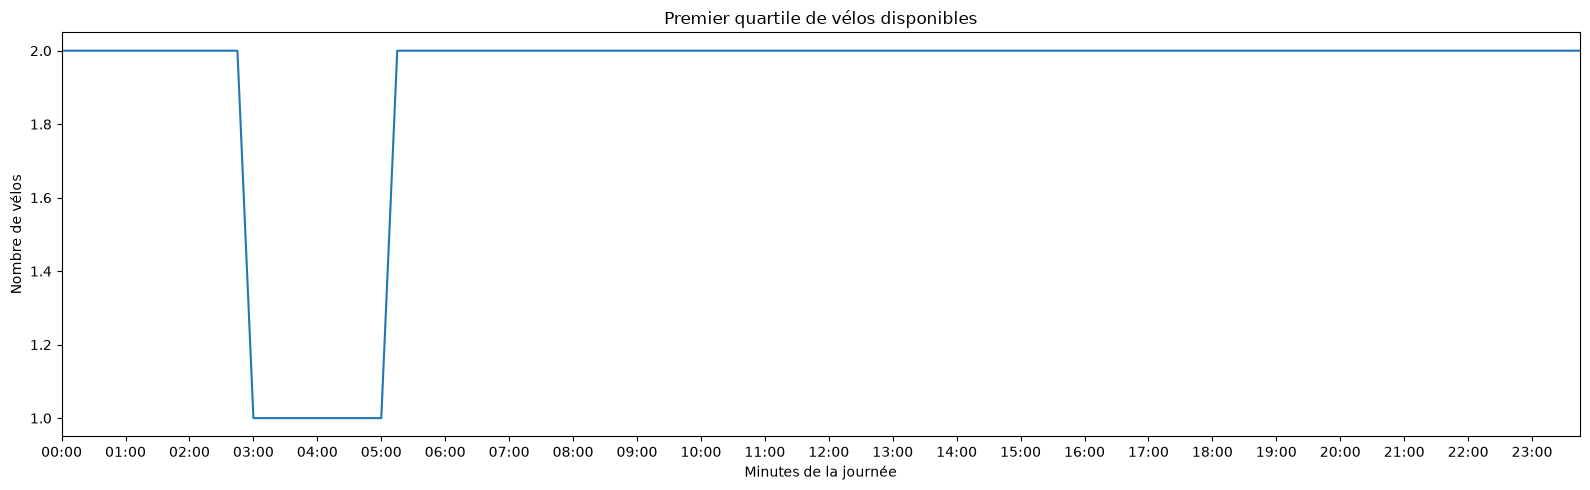

In [68]:
# Moyenne par quart d'heure de l'ensemble des stations
moyenne_station_heure = train.groupby(["heure", "minutes"])["bikes"].quantile(0.25)


# Étiquettes au format HH:MM (0:0 devient 00:00)
liste_minutes = [f"{heure:02d}:{minute:02d}" for heure, minute in moyenne_station_heure.index]

plt.figure(figsize=(16, 5))

plt.plot(liste_minutes, moyenne_station_heure.values)

plt.xlabel("Minutes de la journée")
plt.ylabel("Nombre de vélos")
plt.title(f"Premier quartile de vélos disponibles")

# La courbe commence et finit aux bords du graphique
plt.margins(x=0)

# Une étiquette par heure (toutes les 4 mesures de 15 min) pour rester lisible
plt.xticks(range(0, len(liste_minutes), 4), liste_minutes[::4])

plt.tight_layout()
plt.show()

Entre 3h et 5h du matin, 1/4 des stations ont un nombre de velos disponible inferieur ou égal à 1 sinon 2 pour les heures restantes.

Courbe de la médiane journalière de remplissage de l'ensemble des stations

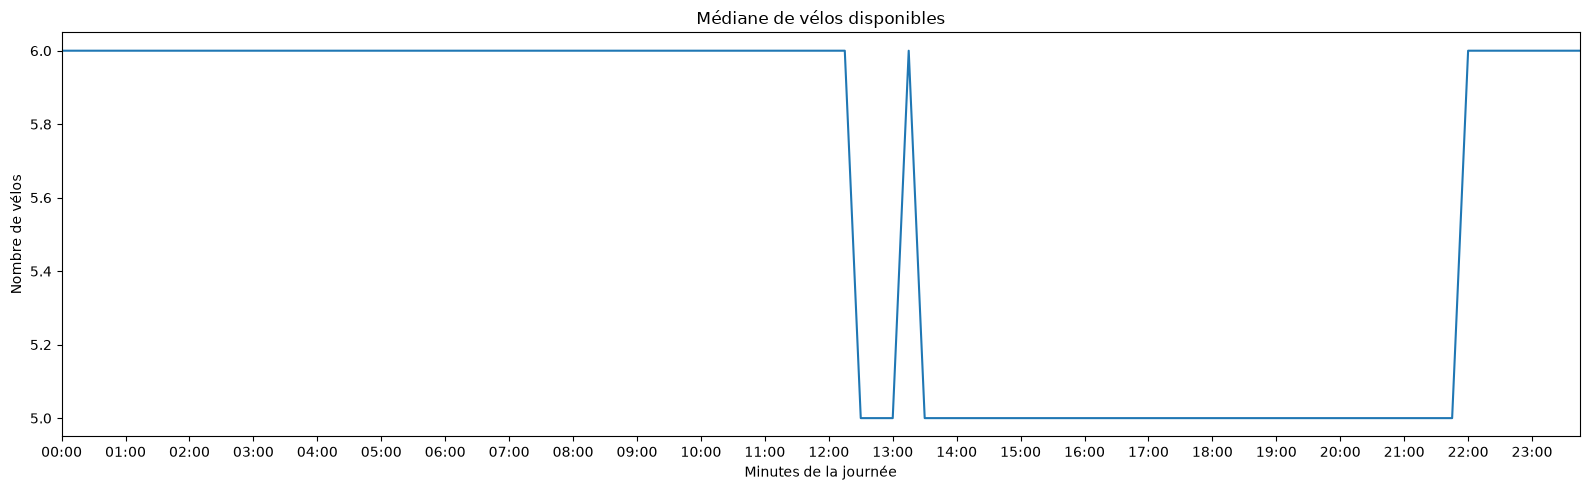

In [69]:
# Moyenne par quart d'heure de l'ensemble des stations
moyenne_station_heure = train.groupby(["heure", "minutes"])["bikes"].quantile(0.5)


# Étiquettes au format HH:MM (0:0 devient 00:00)
liste_minutes = [f"{heure:02d}:{minute:02d}" for heure, minute in moyenne_station_heure.index]

plt.figure(figsize=(16, 5))

plt.plot(liste_minutes, moyenne_station_heure.values)

plt.xlabel("Minutes de la journée")
plt.ylabel("Nombre de vélos")
plt.title(f"Médiane de vélos disponibles")

# La courbe commence et finit aux bords du graphique
plt.margins(x=0)

# Une étiquette par heure (toutes les 4 mesures de 15 min) pour rester lisible
plt.xticks(range(0, len(liste_minutes), 4), liste_minutes[::4])

plt.tight_layout()
plt.show()

A partir de 12h jusqu'à 22h, la moitié des stations ont un nombre de vélos disponible inferieur ou égal à 5, sinon 6 le reste du temps.

Courbe du toisième quartile journalière de remplissage de l'ensemble des stations

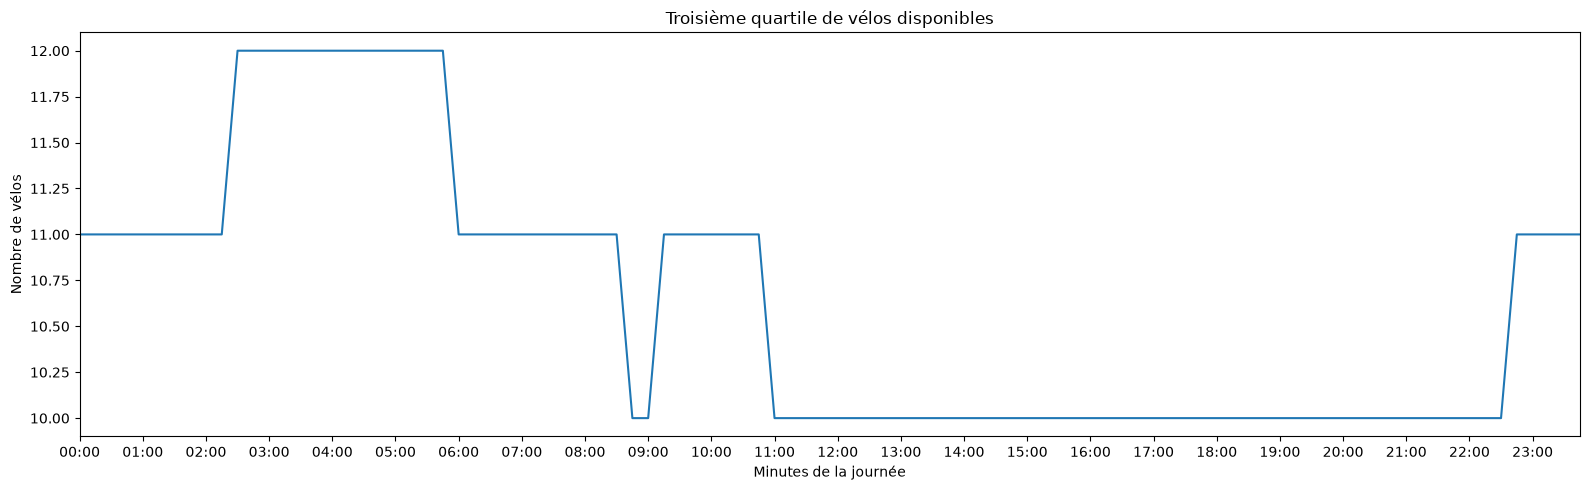

In [70]:
# Moyenne par quart d'heure de l'ensemble des stations
moyenne_station_heure = train.groupby(["heure", "minutes"])["bikes"].quantile(0.75)


# Étiquettes au format HH:MM (0:0 devient 00:00)
liste_minutes = [f"{heure:02d}:{minute:02d}" for heure, minute in moyenne_station_heure.index]

plt.figure(figsize=(16, 5))

plt.plot(liste_minutes, moyenne_station_heure.values)

plt.xlabel("Minutes de la journée")
plt.ylabel("Nombre de vélos")
plt.title(f"Troisième quartile de vélos disponibles")

# La courbe commence et finit aux bords du graphique
plt.margins(x=0)

# Une étiquette par heure (toutes les 4 mesures de 15 min) pour rester lisible
plt.xticks(range(0, len(liste_minutes), 4), liste_minutes[::4])

plt.tight_layout()
plt.show()

Entre 2h et 6h du matin, 3/4 des stations ont un nombre de vélos disponible superieurs ou égal a 12. Entre 23h et 2h ainsi qu'entre 6h et 11h, ce nombre est a 11. Sinon, pour les heures restantes, le nombre disponible descent a 10. 

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Evolution temporelle de remplissage moyen de l'ensemble des stations et déduction des dynamiques urbaines de remplissage en fonction des heures de la journée et de la localisation des stations
</div>
On calcule le taux de remplissage de chaque station à tout instant

In [21]:
train["total"] = train["bikes"] + train["stands"]
train["occupation"] = train["bikes"] / train["total"].replace(0, 1)

Evolution temporelle du taux remplissage moyen de l'ensemble des stations : 5h00

In [22]:
rapport_station_heure = train.groupby(["station", "heure", "minutes"])["occupation"].mean()
matin_bikes = rapport_station_heure.loc[(slice(None), 5, 0)]

m = carte_coloree(matin_bikes, "Taux d'occupation", 0, 1)
m

12h

In [23]:
rapport_station_heure = train.groupby(["station", "heure", "minutes"])["occupation"].mean()
matin_bikes = rapport_station_heure.loc[(slice(None), 12, 0)]

m = carte_coloree(matin_bikes, "Taux d'occupation", 0, 1)
m

23h

In [24]:
rapport_station_heure = train.groupby(["station", "heure", "minutes"])["occupation"].mean()
matin_bikes = rapport_station_heure.loc[(slice(None), 23, 00)]

m = carte_coloree(matin_bikes, "Taux d'occupation", 0, 1)
m

On constate que à 5h du matin, quand tout le monde dort, les stations des zones résidentielles sont bien remplies tandis que les stations du centre-ville sont quasiment vides. <br>
A midi tout le monde travaille donc c'est l'inverse : les zones résidentielles sont quasiment vides tandis que le centre-ville est plein. <br>
Enfin à 23h le centre-ville commence à se vider tandis que les quartiers résidentiels se remplissent.

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Stations renommées
</div>



In [79]:
doublons_coords = stations_toulouse[stations_toulouse.duplicated(subset=["longitude", "latitude"], keep=False)]
g = doublons_coords.groupby(["longitude", "latitude"])["station"].apply(list)
print(g.shape[0], "stations renomés")
print(g.str.len().value_counts())

296 stations renomés
station
2    223
3     62
4     11
Name: count, dtype: int64


296 stations ont étaient renomés, donc plusieurs stations peuvent en faite être la même. 223 stations ont 2 noms différents, 62 en ont 3 et 11 en ont 4.
On observe donc que beaucoup de stations distinctes ont des coordonnées géographique égal entre elle, cela signifie donc que certains décalages de valeurs trouvés auparavant peuvent être expliqué par ce phenomène. Exemple : le nombre d'observation par stations : 1 pique à 100 000, un autre à 50 000 (donc une moitié de station, ceux qui donne 100 000 au final) et un pique à environ 30 000 ou 20 000 ( stations divisées par 3 ou 4 en terme de valeurs).

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Prévision par apprentissage statistique
</div>


<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Fichiers fournis : <br>
- 001_MoyenneGlobale.ipynb <br>
- 003_MoyenneQuartHeure.ipynb <br>
- 100_RegressionLineaire.ipynb
</div>